[Step 1] Environment setup complete. Starting process...

[Step 2] Dataset collected. Sample view:
   Hours_Studied Exam_Status
0       4.370861        Fail
1       9.556429        Pass
2       7.587945        Pass
3       6.387926        Pass
4       2.404168        Fail 

[Step 3] Target class numerical conversion completed:
  Exam_Status  Target_Class
0        Fail             0
1        Pass             1
2        Pass             1
3        Pass             1
4        Fail             0 

[Step 4] Variables separated. Train size: 80, Test size: 20

[Step 5] Logistic regression model successfully initialized.

[Step 6] Model training completed.
       -> Intercept (b0): -7.6206
       -> Slope Coefficient (b1): 1.5582

[Step 7] Computed continuous matrix values (Z) for test items.
[Step 8] Applied sigmoid transformation to convert Z into probabilities.
[Step 9] Thresholding rules applied to finalize predictions.

 [Step 10] PERFORMANCE METRICS EVALUATION
Accuracy Score  : 95.00%
Pr

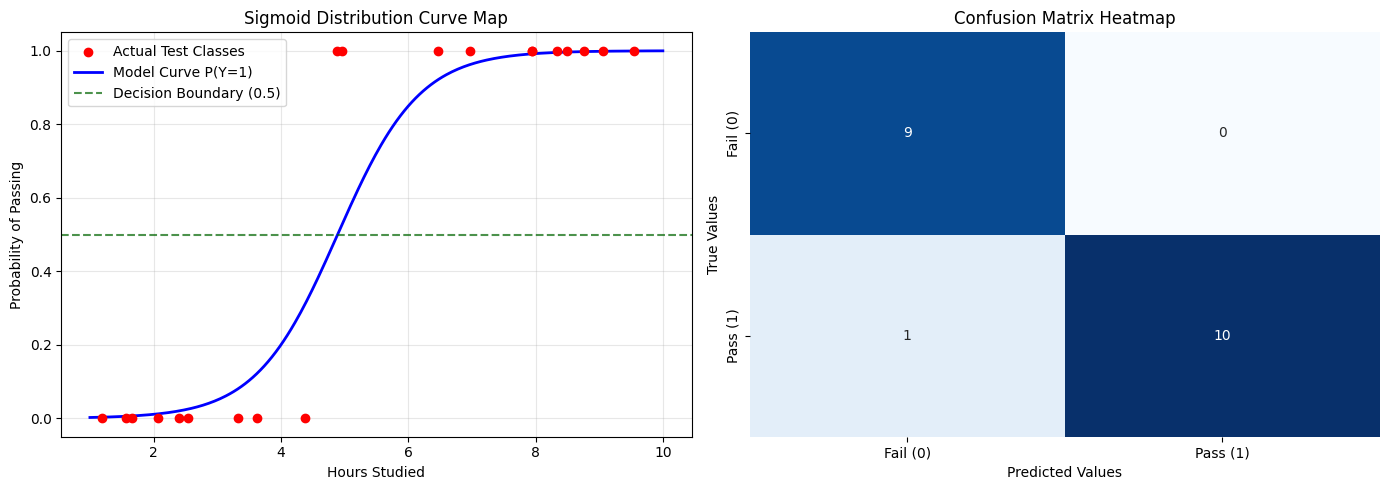


[Step 11] Execution finished. Process stopped successfully.


In [ ]:
# =====================================================================
# BINARY LOGISTIC REGRESSION: FULL ALGORITHMIC PIPELINE
# =====================================================================

# STEP 1: Start
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("[Step 1] Environment setup complete. Starting process...\n")

# STEP 2: Collect dataset containing input features & target classes
np.random.seed(42)
hours_studied = np.random.uniform(1.0, 10.0, 100)
# Underlying true probability distribution for simulation
true_p = 1 / (1 + np.exp(-(1.5 * hours_studied - 7.5)))
raw_outcomes = np.random.binomial(1, true_p)
status_labels = np.where(raw_outcomes == 1, 'Pass', 'Fail')

df = pd.DataFrame({
    'Hours_Studied': hours_studied,
    'Exam_Status': status_labels
})
print("[Step 2] Dataset collected. Sample view:")
print(df.head(), "\n")

# STEP 3: Assign numerical values to target classes (Pass=1, Fail=0)
df['Target_Class'] = df['Exam_Status'].map({'Pass': 1, 'Fail': 0})
print("[Step 3] Target class numerical conversion completed:")
print(df[['Exam_Status', 'Target_Class']].head(), "\n")

# STEP 4: Separate input variables & output variable(s)
X = df[['Hours_Studied']]
y = df['Target_Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"[Step 4] Variables separated. Train size: {len(X_train)}, Test size: {len(X_test)}\n")

# STEP 5: Initialize logistic regression model
model = LogisticRegression()
print("[Step 5] Logistic regression model successfully initialized.\n")

# STEP 6: Train the model using training data to learn the coefficients b0, b1
model.fit(X_train, y_train)
b0 = model.intercept_[0]
b1 = model.coef_[0][0]
print("[Step 6] Model training completed.")
print(f"       -> Intercept (b0): {b0:.4f}")
print(f"       -> Slope Coefficient (b1): {b1:.4f}\n")

# STEP 7: Calculate linear value Z = b0 + b1*x
# Testing steps on the features matrix
Z = b0 + b1 * X_test['Hours_Studied'].values
print("[Step 7] Computed continuous matrix values (Z) for test items.")

# STEP 8: Apply sigmoidal function to calculate Prob P(Y=1) = 1 / (1 + e^-Z)
P = 1 / (1 + np.exp(-Z))
print("[Step 8] Applied sigmoid transformation to convert Z into probabilities.")

# STEP 9: Apply classification threshold (P >= 0.5 -> 1, P < 0.5 -> 0)
predicted_classes = np.where(P >= 0.5, 1, 0)
print("[Step 9] Thresholding rules applied to finalize predictions.\n")

# STEP 10: Evaluate the model using accuracy, precision, recall, F1-score, confusion matrix
acc = accuracy_score(y_test, predicted_classes)
prec = precision_score(y_test, predicted_classes)
rec = recall_score(y_test, predicted_classes)
f1 = f1_score(y_test, predicted_classes)
cm = confusion_matrix(y_test, predicted_classes)

print("=========================================")
print(" [Step 10] PERFORMANCE METRICS EVALUATION")
print("=========================================")
print(f"Accuracy Score  : {acc * 100:.2f}%")
print(f"Precision Score : {prec:.4f}")
print(f"Recall Score    : {rec:.4f}")
print(f"F1-Score        : {f1:.4f}\n")

# Generating evaluation visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Sigmoid Function and Decision Boundary
x_line = np.linspace(1, 10, 300)
z_line = b0 + b1 * x_line
p_line = 1 / (1 + np.exp(-z_line))

axes[0].scatter(X_test, y_test, color='red', marker='o', zorder=5, label='Actual Test Classes')
axes[0].plot(x_line, p_line, color='blue', linewidth=2, label='Model Curve P(Y=1)')
axes[0].axhline(0.5, color='darkgreen', linestyle='--', alpha=0.7, label='Decision Boundary (0.5)')
axes[0].set_title("Sigmoid Distribution Curve Map", fontsize=12)
axes[0].set_xlabel("Hours Studied", fontsize=10)
axes[0].set_ylabel("Probability of Passing", fontsize=10)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot B: Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fail (0)', 'Pass (1)'], yticklabels=['Fail (0)', 'Pass (1)'], ax=axes[1], cbar=False)
axes[1].set_title("Confusion Matrix Heatmap", fontsize=12)
axes[1].set_xlabel("Predicted Values", fontsize=10)
axes[1].set_ylabel("True Values", fontsize=10)

plt.tight_layout()
plt.show()

# STEP 11: Stop
print("\n[Step 11] Execution finished. Process stopped successfully.")
